In [2]:
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
import tensorflow as tf

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Flatten,Conv2D,MaxPooling2D,Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import classification_report , confusion_matrix


In [6]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("Training",X_train.shape)
print("Testing",X_test.shape)



29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training (60000, 28, 28)
Testing (10000, 28, 28)


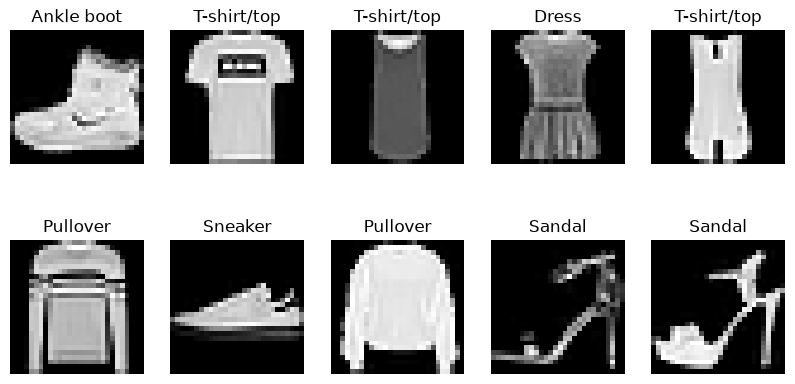

In [10]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

plt.figure(figsize=(10,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.show()


In [11]:
X_train = X_train.astype('float32')/255
X_test = X_test.astype('float32')/255

print(X_train.min(), X_train.max())

0.0 1.0


In [12]:
X_train_ann = X_train.reshape(-1,28*28)
X_test_ann = X_test.reshape(-1,28*28)

print(X_train_ann.shape)
print(X_test_ann.shape)

(60000, 784)
(10000, 784)


In [13]:
ann_model = Sequential([
    Dense(128, activation='relu', input_shape=(784,)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(10, activation= 'softmax')
])


c:\Users\pranj\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
ann_model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [18]:
early_stop = EarlyStopping(
    monitor = 'val_loss',
    patience = 2,
    restore_best_weights = True
)

ann_history = ann_model.fit(
    X_train_ann,
    y_train,
    epochs = 30,
    batch_size = 64,
    validation_split = 0.2,
    callbacks = [early_stop]
)


Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8845 - loss: 0.3096 - val_accuracy: 0.8818 - val_loss: 0.3226
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8886 - loss: 0.3020 - val_accuracy: 0.8866 - val_loss: 0.3173
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8887 - loss: 0.2981 - val_accuracy: 0.8836 - val_loss: 0.3160
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8910 - loss: 0.2905 - val_accuracy: 0.8862 - val_loss: 0.3182
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8924 - loss: 0.2884 - val_accuracy: 0.8852 - val_loss: 0.3159
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8945 - loss: 0.2818 - val_accuracy: 0.8855 - val_loss: 0.3230
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8946 - loss: 0.2775 - val_accuracy: 0.8867 - val_loss: 0.3199


In [19]:
ann_loss, ann_accuracy = ann_model.evaluate(X_test_ann, y_test)
print("loss: ", ann_loss)
print("accuracy: ", ann_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8831 - loss: 0.3362
loss:  0.3361954391002655
accuracy:  0.8830999732017517


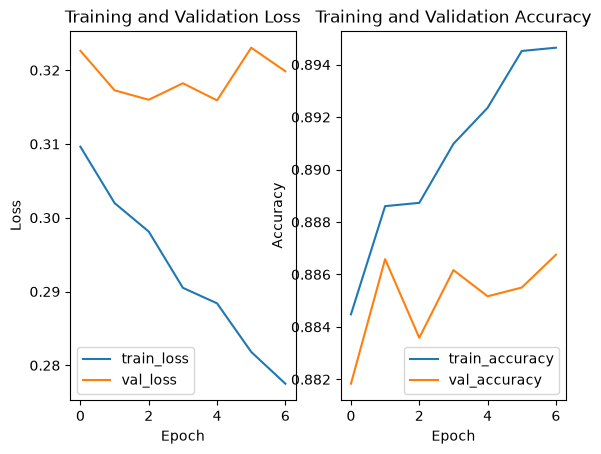

In [20]:
plt.Figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(ann_history.history['loss'], label = 'train_loss')
plt.plot(ann_history.history['val_loss'], label = 'val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.subplot(1,2,2)
plt.plot(ann_history.history['accuracy'], label = 'train_accuracy')
plt.plot(ann_history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.show()

In [21]:
X_train_cnn = X_train.reshape(-1,28,28,1)
X_test_cnn = X_test.reshape(-1,28,28,1)

print(X_train_cnn.shape)
print(X_test_cnn.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [22]:
cnn_model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation= 'softmax')
])


c:\Users\pranj\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [23]:
cnn_model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [24]:
cnn_history = cnn_model.fit(
    X_train_cnn,
    y_train,
    epochs = 30,
    batch_size = 64,
    validation_split = 0.2,
    callbacks = [early_stop]
)

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.7920 - loss: 0.5706 - val_accuracy: 0.8633 - val_loss: 0.3786
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.8645 - loss: 0.3734 - val_accuracy: 0.8818 - val_loss: 0.3253
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.8810 - loss: 0.3244 - val_accuracy: 0.8892 - val_loss: 0.3013
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8907 - loss: 0.2951 - val_accuracy: 0.8916 - val_loss: 0.2902
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9003 - loss: 0.2710 - val_accuracy: 0.9018 - val_loss: 0.2641
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9072 - loss: 0.2520 - val_accuracy: 0.9006 - val_loss: 0.2700
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9129 - loss: 0.2324 - val_accuracy: 0.9036 - val_loss: 0.2607
Epoch 8/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.9195 - loss: 0.2177 - 

In [25]:
cnn_loss, cnn_accuracy = cnn_model.evaluate(
    X_test_cnn,
    y_test
)

print("CNN Test Loss:", cnn_loss)
print("CNN Test Accuracy:", cnn_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9100 - loss: 0.2523
CNN Test Loss: 0.25234904885292053
CNN Test Accuracy: 0.9100000262260437


In [28]:
ann_model.save("fashion_ann.keras")
cnn_model.save("fashion_cnn.keras")